Shape: (30000, 9)
Columns: ['Customer_ID', 'Customer_Type', 'Governorate', 'Age_Band', 'Gender', 'Join_Date', 'Acquisition_Channel', 'Consent_Status', 'Data_Class']
  Customer_ID Customer_Type Governorate  Age_Band    Gender   Join_Date  \
0      C00001        Retail    Dakahlia     45-54      Male  2026-02-22   
1      C00002        Retail     Beheira     35-44      Male  2024-09-30   
2      C00003        Retail    Dakahlia     25-34    Female  2025-06-27   
3      C00004     Wholesale   Port Said  Business  Business  2024-09-27   
4      C00005        Retail     Gharbia       55+    Female  2025-02-07   

  Acquisition_Channel Consent_Status  \
0      Organic Social   Not opted-in   
1   Direct / WhatsApp       Opted-in   
2      Organic Social       Opted-in   
3     Wholesale Sales       Opted-in   
4         Paid Social   Not opted-in   

                                          Data_Class  
0  Modeled/anonymized training customer - not act...  
1  Modeled/anonymized training cu

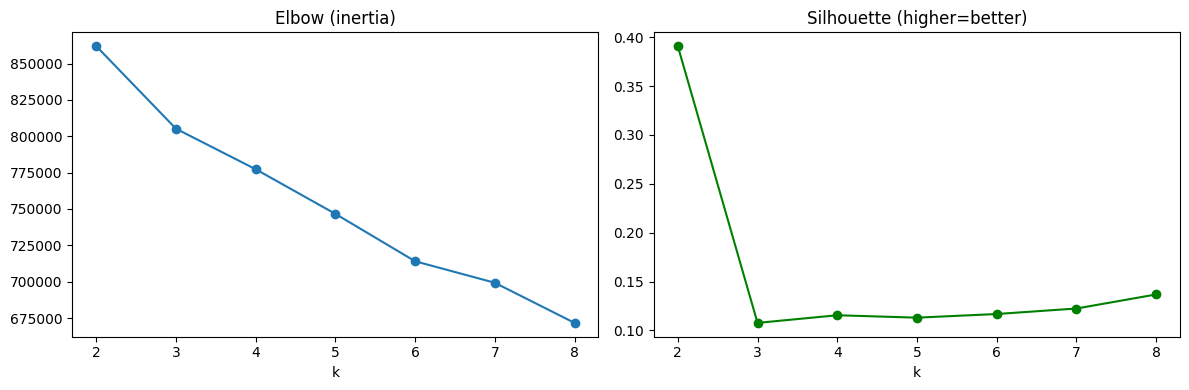


--- Segment x Customer_Type ---
Customer_Type  Retail  Wholesale
Segment                         
0                 565          0
1               17749          0
2                   0       1651
3               10035          0

--- Segment x Governorate (top 6) ---
Governorate  Alexandria  Beheira  Cairo  Dakahlia  Damietta  Gharbia
Segment                                                             
0                     0        0      0         0       565        0
1                  5111     1433   3236      1126         0     1088
2                   484      132    295        96        34       94
3                  2820      809   1852       629         0      596

--- Segment x Acquisition_Channel (top 6) ---
Acquisition_Channel  Direct / WhatsApp  Google Search  Organic Social  \
Segment                                                                 
0                                  118             60             122   
1                                 3989           2

In [1]:
# ============================================================
# NOTEBOOK 04 — AI SEGMENTATION (K-Means, unsupervised ML)
# Goal: find hidden customer groups for the Customer 360 story
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# ---------- 0. LOAD DATA (the part that was missing) ----------
Data_DIR = Path("../Data/Raw")
customers = pd.read_csv(Data_DIR / "Customers.csv")

# Sanity check — confirm the dataframe is correct BEFORE clustering
print("Shape:", customers.shape)                 # expect (30000, 9)
print("Columns:", customers.columns.tolist())    # expect the 9 known columns
print(customers.head())

# ---------- 1. Pick the descriptive columns we cluster on ----------
# (drop IDs, dates, and the data-class label — they add no grouping signal)
cluster_cols = ["Customer_Type", "Governorate", "Age_Band",
                "Gender", "Acquisition_Channel", "Consent_Status"]

X_cat = pd.get_dummies(customers[cluster_cols], drop_first=False).astype(float)
print("One-hot matrix shape:", X_cat.shape)

# ---------- 2. SCALE (mandatory for K-Means) ----------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cat)

# ---------- 3. Choose k with elbow + silhouette ----------
inertias, silhouettes = [], []
ks = range(2, 9)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inertias, "o-"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), silhouettes, "o-", color="green"); ax[1].set_title("Silhouette (higher=better)"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

# ---------- 4. Fit the chosen model (start with k=4; adjust after plots) ----------
K = 4
km_final = KMeans(n_clusters=K, n_init=10, random_state=42)
customers["Segment"] = km_final.fit_predict(X_scaled)

# ---------- 5. NAME the clusters in business language ----------
print("\n--- Segment x Customer_Type ---")
print(pd.crosstab(customers["Segment"], customers["Customer_Type"]))

print("\n--- Segment x Governorate (top 6) ---")
print(pd.crosstab(customers["Segment"], customers["Governorate"]).iloc[:, :6])

print("\n--- Segment x Acquisition_Channel (top 6) ---")
print(pd.crosstab(customers["Segment"], customers["Acquisition_Channel"]).iloc[:, :6])

# ---------- 6. Save artifacts for the Streamlit app ----------
import joblib
Path("../models").mkdir(exist_ok=True)
joblib.dump(km_final, "../models/kmeans_segments.pkl")
joblib.dump(scaler, "../models/segment_scaler.pkl")
X_cat.columns.to_series().to_csv("../models/segment_columns.csv", index=False)
print("\nSegmentation model saved to ../models/")


--- Segment x Age_Band ---
Age_Band  18-24  25-34  35-44  45-54   55+  Business
Segment                                             
0            46    228    166     87    38         0
1          1722   6685   5629   2630  1083         0
2             0      0      0      0     0      1651
3           913   3792   3145   1582   603         0

--- Segment x Gender ---
Gender   Business  Female  Male  Not specified
Segment                                       
0               0     372   175             18
1               0   11878  5324            547
2            1651       0     0              0
3               0    6681  3049            305

--- Segment x Consent_Status ---
Consent_Status  Not opted-in  Opted-in
Segment                               
0                        202       363
1                          0     17749
2                        576      1075
3                      10035         0


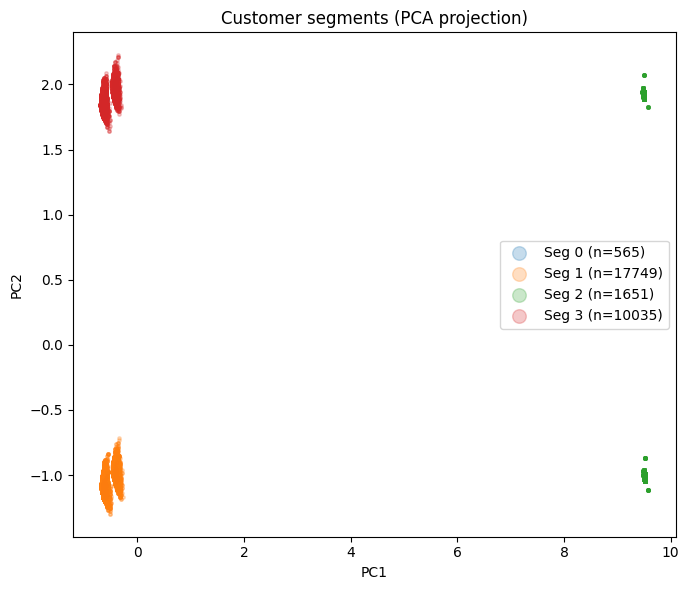


--- k=3 (no scaling) x Customer_Type ---
Customer_Type  Retail  Wholesale
Segment_k3_ns                   
0                5994       1075
1               10237        576
2               12118          0

--- k=3 (no scaling) x Age_Band ---
Age_Band       18-24  25-34  35-44  45-54  55+  Business
Segment_k3_ns                                           
0                575   2228   1957    870  364      1075
1                928   3878   3199   1616  616       576
2               1178   4599   3784   1813  744         0


In [5]:
# ---- A. Reveal what separates retail segments 1 vs 3 ----
for col in ["Age_Band", "Gender", "Consent_Status"]:
    print(f"\n--- Segment x {col} ---")
    print(pd.crosstab(customers["Segment"], customers[col]))

# ---- B. Visual check: PCA down to 2 dims, color by segment ----
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(7, 6))
for s in sorted(customers["Segment"].unique()):
    mask = customers["Segment"] == s
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], alpha=0.25, s=6, label=f"Seg {s} (n={mask.sum()})")
plt.legend(markerscale=4); plt.title("Customer segments (PCA projection)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.tight_layout(); plt.show()

# ---- C. Optional: k=3 without scaling, to test the Damietta-artifact theory ----
from sklearn.cluster import KMeans
km3_noscale = KMeans(n_clusters=3, n_init=10, random_state=42)
customers["Segment_k3_ns"] = km3_noscale.fit_predict(X_cat)   # NOTE: X_cat, NOT X_scaled
print("\n--- k=3 (no scaling) x Customer_Type ---")
print(pd.crosstab(customers["Segment_k3_ns"], customers["Customer_Type"]))
print("\n--- k=3 (no scaling) x Age_Band ---")
print(pd.crosstab(customers["Segment_k3_ns"], customers["Age_Band"]))

In [6]:
import joblib
from pathlib import Path
Path("../models").mkdir(exist_ok=True)
# example: keep the k=4 scaled model you already saved; or save the chosen one:
# joblib.dump(chosen_km, "../models/kmeans_segments.pkl")
# joblib.dump(chosen_scaler_or_None, "../models/segment_scaler.pkl")
# X_cat.columns.to_series().to_csv("../models/segment_columns.csv", index=False)
print("Locked.")

Locked.
